# 001 — manual Tracker annotation vs MediaPipe ankle and sacral proxies

This notebook compares the existing manual annotation with the pose pipeline. It does **not** try to measure impact acceleration from video.

- **Manual source:** `invexp/walkTest/normalized/001_120fps_ffv1.csv`, exported from Tracker.
  - mass **A** = waist / sacrum.
  - mass **B** = ankle.
- **Pose source:** `$INVEXP_DATA_DIR/derived/pose/001_landmarks.csv.gz`, produced by `invexp_pose`.
- **Ankle proxy:** MediaPipe `left_ankle`.
  - This is the anatomically matching point for manual mass **B**.
- **Foot sensitivity proxy:** midpoint of MediaPipe `left_heel` and `left_foot_index` in x, lowest of the two in y.
  - The earlier pipeline validation used this point. It is retained here as a sensitivity row because it behaves differently from the ankle joint.
- **Sacral proxy:** midpoint of MediaPipe `left_hip` and `right_hip`.
  - MediaPipe has no sacrum landmark. The hip midpoint is a pelvis-centre proxy, not the same point as the manual waist marker.

Coordinates are converted to **source pixels**:

- Tracker world → pixels with the calibration stored in the `.trk` file.
- MediaPipe normalized → pixels with the source frame size.

Primary agreement metric is **centred RMSE**, because the two methods mark different anatomical points. Raw offsets and Bland–Altman limits are also reported. Nothing is interpolated across gaps.

Impact acceleration remains the IMU channel. Pose-derived second derivatives are not used here.


In [1]:
import os
import xml.etree.ElementTree as ET
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

VIDEO_ID = "001"
FS = 120.0
VIS_THRESHOLD = 0.5
EVENT_MIN_DIST_S = 0.5
EVENT_DEPTH_WORLD = 0.03
EVENT_HALFWIDTH_S = 0.25


def repo_root() -> Path:
    here = Path.cwd().resolve()
    for path in [here, *here.parents]:
        if (path / "pixi.toml").exists() and (path / "invexp").is_dir():
            return path
    raise FileNotFoundError("run this notebook from inside the uni repository")


ROOT = repo_root()
DATA_DIR = Path(
    os.environ.get(
        "INVEXP_DATA_DIR",
        Path.home() / "Documents/University/XII/InvExp/data",
    )
).expanduser()

MANUAL_CSV = ROOT / "invexp/walkTest/normalized" / f"{VIDEO_ID}_120fps_ffv1.csv"
TRACKER_XML = ROOT / "invexp/walkTest" / f"{VIDEO_ID}_120fps_ffv1.trk"
POSE_LANDMARKS = DATA_DIR / "derived/pose" / f"{VIDEO_ID}_landmarks.csv.gz"
POSE_EVENTS = ROOT / "invexp/walkTest/pose" / f"{VIDEO_ID}_events.csv"
OUT_CSV = ROOT / "invexp/walkTest/pose" / f"{VIDEO_ID}_manual_vs_pose.csv"

paths = {
    "manual CSV": MANUAL_CSV,
    "Tracker XML": TRACKER_XML,
    "pose landmarks": POSE_LANDMARKS,
    "pose events": POSE_EVENTS,
}
for label, path in paths.items():
    print(f"{label:16s} {path}  {'OK' if path.exists() else 'MISSING'}")

missing = [label for label, path in paths.items() if not path.exists()]
if missing:
    raise FileNotFoundError("missing inputs: " + ", ".join(missing))


manual CSV       /Users/rifusaki/localRepos/uni/invexp/walkTest/normalized/001_120fps_ffv1.csv  OK
Tracker XML      /Users/rifusaki/localRepos/uni/invexp/walkTest/001_120fps_ffv1.trk  OK
pose landmarks   /Users/rifusaki/Documents/University/XII/InvExp/data/derived/pose/001_landmarks.csv.gz  OK
pose events      /Users/rifusaki/localRepos/uni/invexp/walkTest/pose/001_events.csv  OK


In [2]:
def read_tracker_properties(path: Path) -> dict[str, str]:
    root = ET.parse(path).getroot()
    properties: dict[str, str] = {}
    for node in root.iter("property"):
        name = node.get("name")
        if name and node.text and name not in properties:
            properties[name] = node.text.strip()
    return properties


props = read_tracker_properties(TRACKER_XML)
START_FRAME = int(props["startframe"])
TRACKER_FPS = float(props["frame_rate"])
X_ORIGIN = float(props["xorigin"])
Y_ORIGIN = float(props["yorigin"])
X_SCALE = float(props["xscale"])
Y_SCALE = float(props["yscale"])

print("Tracker calibration")
print(f"  start frame : {START_FRAME}")
print(f"  frame rate  : {TRACKER_FPS:g} fps")
print(f"  origin      : ({X_ORIGIN:.3f}, {Y_ORIGIN:.3f}) px")
print(f"  scale       : x={X_SCALE:.6f}  y={Y_SCALE:.6f} px/unit")
print(f"  video frames: {props.get('frame_count', '?')}")


Tracker calibration
  start frame : 1286
  frame rate  : 120 fps
  origin      : (137.875, 733.500) px
  scale       : x=435.923305  y=435.923305 px/unit
  video frames: 3126


In [3]:
raw = pd.read_csv(
    MANUAL_CSV,
    skiprows=3,
    header=None,
    names=["t", "xA", "yA", "xB", "yB"],
    dtype=float,
)

manual = pd.DataFrame(
    {
        "frame": START_FRAME + np.rint(raw["t"].to_numpy() * TRACKER_FPS).astype(int),
        "t": raw["t"].to_numpy(),
        "waist_x_px": X_ORIGIN + X_SCALE * raw["xA"].to_numpy(),
        "waist_y_px": Y_ORIGIN - Y_SCALE * raw["yA"].to_numpy(),
        "ankle_x_px": X_ORIGIN + X_SCALE * raw["xB"].to_numpy(),
        "ankle_y_px": Y_ORIGIN - Y_SCALE * raw["yB"].to_numpy(),
    }
)


def segments(mask: np.ndarray):
    idx = np.flatnonzero(mask)
    if len(idx) == 0:
        return []
    return [
        (int(part[0]), int(part[-1]))
        for part in np.split(idx, np.flatnonzero(np.diff(idx) > 1) + 1)
    ]


print(f"{len(manual)} manual rows, frames {manual.frame.min()}–{manual.frame.max()}")
print(f"time {manual.t.min():.3f}–{manual.t.max():.3f} s")
for label, col in [("waist", "waist_x_px"), ("ankle", "ankle_x_px")]:
    mask = manual[col].notna().to_numpy()
    print(f"\n{label}: {mask.sum()}/{len(mask)} samples ({100 * mask.mean():.1f}%)")
    for start, stop in segments(mask):
        print(f"   {manual.t.iloc[start]:6.3f}–{manual.t.iloc[stop]:6.3f} s")


387 manual rows, frames 1286–1672
time 0.000–3.217 s

waist: 288/387 samples (74.4%)
    0.025– 0.333 s
    1.008– 1.258 s
    1.400– 3.217 s

ankle: 364/387 samples (94.1%)
    0.000– 3.025 s


In [4]:
landmarks = pd.read_csv(POSE_LANDMARKS)
required = {"frame", "pts_s", "width_px", "height_px", "name", "x", "y", "visibility"}
missing = sorted(required - set(landmarks.columns))
if missing:
    raise ValueError("pose landmark table missing columns: " + ", ".join(missing))

WIDTH = int(landmarks["width_px"].dropna().iloc[0])
HEIGHT = int(landmarks["height_px"].dropna().iloc[0])

wide = (
    landmarks.pivot(
        index=["frame", "pts_s"],
        columns="name",
        values=["x", "y", "visibility"],
    )
    .sort_index()
)
wide.columns = [f"{field}_{name}" for field, name in wide.columns]
wide = wide.reset_index()

for name in (
    "left_ankle",
    "left_hip",
    "right_hip",
    "left_heel",
    "left_foot_index",
):
    if f"x_{name}" not in wide.columns:
        raise ValueError(f"pose landmark missing: {name}")
    wide[f"{name}_x_px"] = wide[f"x_{name}"] * WIDTH
    wide[f"{name}_y_px"] = wide[f"y_{name}"] * HEIGHT

wide["pose_ankle_x_px"] = wide["left_ankle_x_px"]
wide["pose_ankle_y_px"] = wide["left_ankle_y_px"]
wide["pose_ankle_vis"] = wide["visibility_left_ankle"]
wide["pose_ankle_valid"] = (
    wide[["left_ankle_x_px", "left_ankle_y_px"]].notna().all(axis=1)
    & (wide["pose_ankle_vis"] >= VIS_THRESHOLD)
)

wide["foot_x_px"] = (wide["left_heel_x_px"] + wide["left_foot_index_x_px"]) / 2.0
wide["foot_y_px"] = wide[["left_heel_y_px", "left_foot_index_y_px"]].max(axis=1)
wide["foot_vis"] = wide[["visibility_left_heel", "visibility_left_foot_index"]].min(axis=1)
wide["foot_valid"] = (
    wide[["left_heel_x_px", "left_heel_y_px", "left_foot_index_x_px", "left_foot_index_y_px"]]
    .notna()
    .all(axis=1)
    & (wide["foot_vis"] >= VIS_THRESHOLD)
)

wide["sacrum_x_px"] = (wide["left_hip_x_px"] + wide["right_hip_x_px"]) / 2.0
wide["sacrum_y_px"] = (wide["left_hip_y_px"] + wide["right_hip_y_px"]) / 2.0
wide["sacrum_vis"] = wide[["visibility_left_hip", "visibility_right_hip"]].min(axis=1)
wide["sacrum_valid"] = (
    wide[["left_hip_x_px", "left_hip_y_px", "right_hip_x_px", "right_hip_y_px"]]
    .notna()
    .all(axis=1)
    & (wide["sacrum_vis"] >= VIS_THRESHOLD)
)

print(f"pose frame size: {WIDTH} x {HEIGHT}")
print(f"pose rows: {len(wide)}; detected: {wide['visibility_left_heel'].notna().sum()}")
print(f"ankle valid: {wide.pose_ankle_valid.sum()}; foot valid: {wide.foot_valid.sum()}; sacrum valid: {wide.sacrum_valid.sum()}")
print(wide[["frame", "pts_s", "pose_ankle_x_px", "pose_ankle_y_px", "foot_x_px", "foot_y_px", "sacrum_x_px", "sacrum_y_px"]].head())


pose frame size: 1920 x 1080
pose rows: 3126; detected: 411
ankle valid: 402; foot valid: 402; sacrum valid: 404
   frame     pts_s  pose_ankle_x_px  pose_ankle_y_px  foot_x_px  foot_y_px  \
0      0  0.000000              NaN              NaN        NaN        NaN   
1      1  0.008333              NaN              NaN        NaN        NaN   
2      2  0.016667              NaN              NaN        NaN        NaN   
3      3  0.025000              NaN              NaN        NaN        NaN   
4      4  0.033333              NaN              NaN        NaN        NaN   

   sacrum_x_px  sacrum_y_px  
0          NaN          NaN  
1          NaN          NaN  
2          NaN          NaN  
3          NaN          NaN  
4          NaN          NaN  


In [5]:
pose_cols = [
    "frame",
    "pts_s",
    "pose_ankle_x_px",
    "pose_ankle_y_px",
    "pose_ankle_vis",
    "pose_ankle_valid",
    "foot_x_px",
    "foot_y_px",
    "foot_vis",
    "foot_valid",
    "sacrum_x_px",
    "sacrum_y_px",
    "sacrum_vis",
    "sacrum_valid",
]
merged = manual.merge(wide[pose_cols], on="frame", how="inner")
merged["t_rel"] = merged["pts_s"] - merged["pts_s"].iloc[0]

manual_start_s = float(wide.loc[wide["frame"] == START_FRAME, "pts_s"].iloc[0])
merged["ankle_ready"] = merged["pose_ankle_valid"].fillna(False) & merged["ankle_x_px"].notna()
merged["foot_ready"] = merged["foot_valid"].fillna(False) & merged["ankle_x_px"].notna()
merged["sacrum_ready"] = merged["sacrum_valid"].fillna(False) & merged["waist_x_px"].notna()

print(f"overlap: {len(merged)} frames, {merged.t_rel.min():.3f}–{merged.t_rel.max():.3f} s")
print(f"ankle ready: {merged.ankle_ready.sum()}")
print(f"foot (heel/toe) ready: {merged.foot_ready.sum()}")
print(f"sacrum ready: {merged.sacrum_ready.sum()}")
print(f"manual start in source clock: {manual_start_s:.6f} s")


overlap: 387 frames, 0.000–3.218 s
ankle ready: 361
foot (heel/toe) ready: 361
sacrum ready: 288
manual start in source clock: 10.722500 s


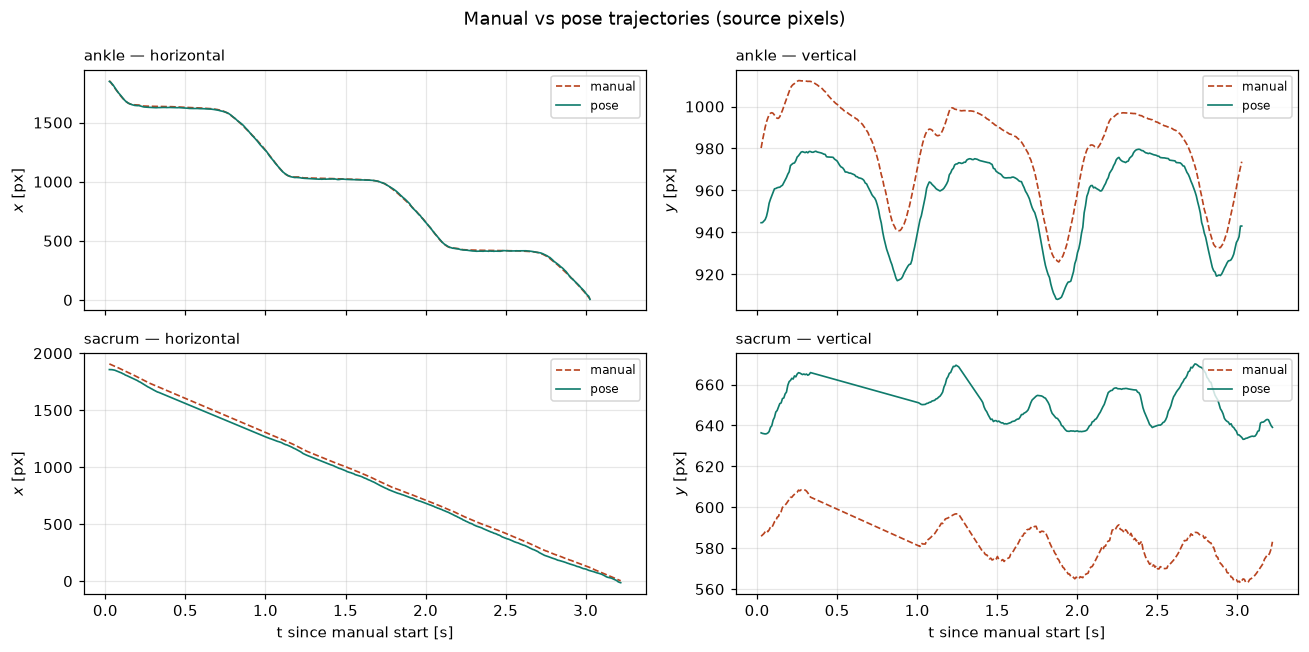

In [6]:
def plot_series(ax, x, manual_y, pose_y, title, ylabel):
    ax.plot(x, manual_y, color="#b8431f", lw=1.1, ls="--", label="manual")
    ax.plot(x, pose_y, color="#0f7b6c", lw=1.1, label="pose")
    ax.set_title(title, loc="left", fontsize=10)
    ax.set_ylabel(ylabel)
    ax.legend(loc="upper right", fontsize=8)


ankle = merged[merged.ankle_ready]
sacrum = merged[merged.sacrum_ready]

fig, axes = plt.subplots(2, 2, figsize=(12, 6), sharex=True)
plot_series(axes[0, 0], ankle.t_rel, ankle.ankle_x_px, ankle.pose_ankle_x_px, "ankle — horizontal", "$x$ [px]")
plot_series(axes[0, 1], ankle.t_rel, ankle.ankle_y_px, ankle.pose_ankle_y_px, "ankle — vertical", "$y$ [px]")
plot_series(axes[1, 0], sacrum.t_rel, sacrum.waist_x_px, sacrum.sacrum_x_px, "sacrum — horizontal", "$x$ [px]")
plot_series(axes[1, 1], sacrum.t_rel, sacrum.waist_y_px, sacrum.sacrum_y_px, "sacrum — vertical", "$y$ [px]")
for ax in axes[1]:
    ax.set_xlabel("t since manual start [s]")
fig.suptitle("Manual vs pose trajectories (source pixels)")
fig.tight_layout()
plt.show()


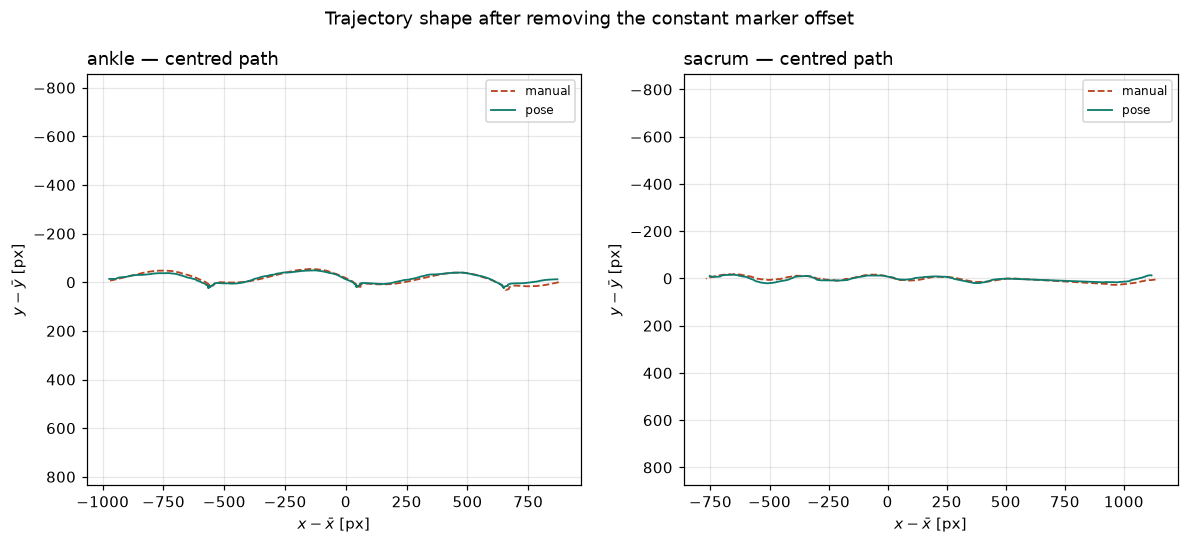

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))

for ax, data, label in [(axes[0], ankle, "ankle"), (axes[1], sacrum, "sacrum")]:
    if label == "ankle":
        mx, my = data.ankle_x_px, data.ankle_y_px
        px, py = data.pose_ankle_x_px, data.pose_ankle_y_px
    else:
        mx, my = data.waist_x_px, data.waist_y_px
        px, py = data.sacrum_x_px, data.sacrum_y_px

    ax.plot(mx - mx.mean(), my - my.mean(), color="#b8431f", lw=1.2, ls="--", label="manual")
    ax.plot(px - px.mean(), py - py.mean(), color="#0f7b6c", lw=1.2, label="pose")
    ax.set_title(f"{label} — centred path", loc="left")
    ax.set_xlabel("$x - \\bar{x}$ [px]")
    ax.set_ylabel("$y - \\bar{y}$ [px]")
    ax.invert_yaxis()
    ax.set_aspect("equal", adjustable="datalim")
    ax.legend(fontsize=8)

fig.suptitle("Trajectory shape after removing the constant marker offset")
fig.tight_layout()
plt.show()


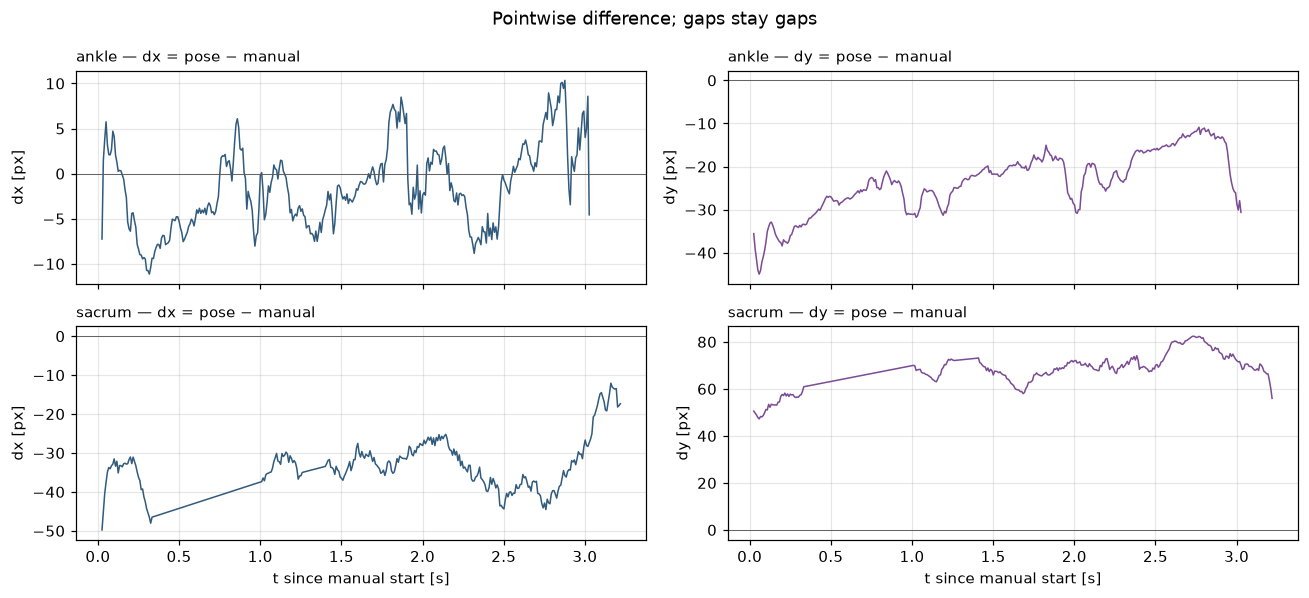

In [8]:
ankle = merged[merged.ankle_ready].copy()
foot_alt = merged[merged.foot_ready].copy()
sacrum = merged[merged.sacrum_ready].copy()
ankle["dx"] = ankle.pose_ankle_x_px - ankle.ankle_x_px
ankle["dy"] = ankle.pose_ankle_y_px - ankle.ankle_y_px
foot_alt["dx"] = foot_alt.foot_x_px - foot_alt.ankle_x_px
foot_alt["dy"] = foot_alt.foot_y_px - foot_alt.ankle_y_px
sacrum["dx"] = sacrum.sacrum_x_px - sacrum.waist_x_px
sacrum["dy"] = sacrum.sacrum_y_px - sacrum.waist_y_px

fig, axes = plt.subplots(2, 2, figsize=(12, 5.5), sharex=True)
for row, data, label in [(0, ankle, "ankle"), (1, sacrum, "sacrum")]:
    axes[row, 0].plot(data.t_rel, data.dx, color="#315b7d", lw=1.0)
    axes[row, 0].axhline(0, color="0.35", lw=0.6)
    axes[row, 0].set_title(f"{label} — dx = pose − manual", loc="left", fontsize=10)
    axes[row, 0].set_ylabel("dx [px]")

    axes[row, 1].plot(data.t_rel, data.dy, color="#7b4b94", lw=1.0)
    axes[row, 1].axhline(0, color="0.35", lw=0.6)
    axes[row, 1].set_title(f"{label} — dy = pose − manual", loc="left", fontsize=10)
    axes[row, 1].set_ylabel("dy [px]")

for ax in axes[1]:
    ax.set_xlabel("t since manual start [s]")
fig.suptitle("Pointwise difference; gaps stay gaps")
fig.tight_layout()
plt.show()


In [9]:
def error_stats(manual_x, manual_y, pose_x, pose_y):
    dx = np.asarray(pose_x, dtype=float) - np.asarray(manual_x, dtype=float)
    dy = np.asarray(pose_y, dtype=float) - np.asarray(manual_y, dtype=float)
    ok = np.isfinite(dx) & np.isfinite(dy)
    dx, dy = dx[ok], dy[ok]
    centered_dx = dx - dx.mean()
    centered_dy = dy - dy.mean()

    def rmse(values):
        return float(np.sqrt(np.mean(values**2)))

    sd_x = float(dx.std(ddof=1)) if len(dx) > 1 else 0.0
    sd_y = float(dy.std(ddof=1)) if len(dy) > 1 else 0.0
    return {
        "n": int(len(dx)),
        "mean_dx_px": float(dx.mean()),
        "mean_dy_px": float(dy.mean()),
        "raw_rmse_x_px": rmse(dx),
        "raw_rmse_y_px": rmse(dy),
        "raw_rmse_r_px": rmse(np.hypot(dx, dy)),
        "centered_rmse_x_px": rmse(centered_dx),
        "centered_rmse_y_px": rmse(centered_dy),
        "centered_rmse_r_px": rmse(np.hypot(centered_dx, centered_dy)),
        "ba_x_low_px": float(dx.mean() - 1.96 * sd_x),
        "ba_x_high_px": float(dx.mean() + 1.96 * sd_x),
        "ba_y_low_px": float(dy.mean() - 1.96 * sd_y),
        "ba_y_high_px": float(dy.mean() + 1.96 * sd_y),
    }


stats = pd.DataFrame(
    [
        {"proxy": "ankle", **error_stats(ankle.ankle_x_px, ankle.ankle_y_px, ankle.pose_ankle_x_px, ankle.pose_ankle_y_px)},
        {"proxy": "foot (heel/toe)", **error_stats(foot_alt.ankle_x_px, foot_alt.ankle_y_px, foot_alt.foot_x_px, foot_alt.foot_y_px)},
        {"proxy": "sacrum", **error_stats(sacrum.waist_x_px, sacrum.waist_y_px, sacrum.sacrum_x_px, sacrum.sacrum_y_px)},
    ]
).set_index("proxy")

display(stats.round(2).T)


proxy,ankle,foot (heel/toe),sacrum
n,361.00,361.00,288.00
mean_dx_px,-1.51,-19.69,-32.95
mean_dy_px,-23.59,25.28,68.06
raw_rmse_x_px,4.80,27.12,33.60
raw_rmse_y_px,24.62,33.72,68.47
raw_rmse_r_px,25.08,43.28,76.27
centered_rmse_x_px,4.56,18.65,6.58
centered_rmse_y_px,7.02,22.31,7.47
centered_rmse_r_px,8.37,29.08,9.95
ba_x_low_px,-10.46,-56.30,-45.87


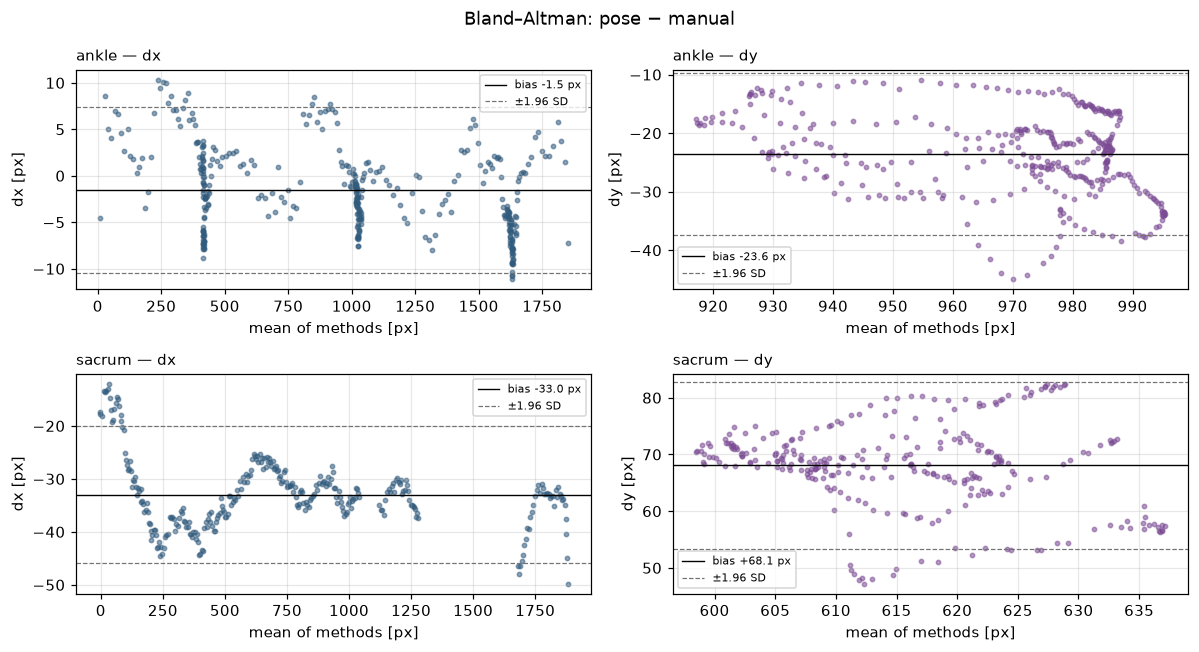

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6))
pairs = [
    ("ankle", ankle, "ankle_x_px", "ankle_y_px", "pose_ankle_x_px", "pose_ankle_y_px"),
    ("sacrum", sacrum, "waist_x_px", "waist_y_px", "sacrum_x_px", "sacrum_y_px"),
]
for row, (label, data, manual_x, manual_y, pose_x, pose_y) in enumerate(pairs):
    for col, comp in enumerate(["dx", "dy"]):
        ax = axes[row, col]
        diff = data[comp].to_numpy()
        if comp == "dx":
            mean = (data[pose_x] + data[manual_x]).to_numpy() / 2.0
        else:
            mean = (data[pose_y] + data[manual_y]).to_numpy() / 2.0
        ax.scatter(mean, diff, s=8, alpha=0.55, color="#315b7d" if comp == "dx" else "#7b4b94")
        bias = diff.mean()
        sd = diff.std(ddof=1)
        ax.axhline(bias, color="k", lw=0.9, label=f"bias {bias:+.1f} px")
        ax.axhline(bias + 1.96 * sd, color="0.45", lw=0.8, ls="--", label="±1.96 SD")
        ax.axhline(bias - 1.96 * sd, color="0.45", lw=0.8, ls="--")
        ax.set_title(f"{label} — {comp}", loc="left", fontsize=10)
        ax.set_xlabel("mean of methods [px]")
        ax.set_ylabel(f"{comp} [px]")
        ax.legend(fontsize=7, loc="best")

fig.suptitle("Bland–Altman: pose − manual")
fig.tight_layout()
plt.show()


In [11]:
def find_events(y: np.ndarray, mask: np.ndarray, depth: float):
    distance = int(round(EVENT_MIN_DIST_S * FS))
    halfwidth = int(round(EVENT_HALFWIDTH_S * FS))
    candidates = []
    for index in range(1, len(y) - 1):
        if not (mask[index - 1] and mask[index] and mask[index + 1]):
            continue
        if y[index] < y[index - 1] and y[index] <= y[index + 1]:
            envelope = y[max(0, index - halfwidth) : index + halfwidth + 1]
            if y[index] <= np.nanmax(envelope) - depth:
                candidates.append(index)

    kept = []
    for index in sorted(candidates, key=lambda i: y[i]):
        if all(abs(index - other) >= distance for other in kept):
            kept.append(index)
    return np.sort(np.array(kept, dtype=int))


frame_to_pts = wide.set_index("frame")["pts_s"]
manual_start_s = float(frame_to_pts.loc[START_FRAME])

manual_y = raw["yB"].to_numpy(dtype=float)
manual_mask = np.isfinite(raw["xB"].to_numpy(dtype=float)) & np.isfinite(manual_y)
manual_idx = find_events(manual_y, manual_mask, EVENT_DEPTH_WORLD)
manual_events = pd.DataFrame(
    {
        "kind": "manual ankle low",
        "frame": START_FRAME + np.rint(raw["t"].to_numpy()[manual_idx] * TRACKER_FPS).astype(int),
        "t_rel": raw["t"].to_numpy()[manual_idx],
    }
)
manual_events["abs_s"] = manual_events["frame"].map(frame_to_pts)

in_manual_range = wide["frame"].between(START_FRAME, manual.frame.max())
pose_mask = wide["pose_ankle_valid"].fillna(False).to_numpy() & in_manual_range.to_numpy()
# World y grows upward, image y grows downward. The manual detector runs on
# world y, so negate pose image y to search for the same stance low.
pose_stance_signal = -wide["pose_ankle_y_px"].to_numpy(dtype=float)
pose_idx = find_events(
    pose_stance_signal,
    pose_mask,
    EVENT_DEPTH_WORLD * Y_SCALE,
)
pose_lows = pd.DataFrame(
    {
        "kind": "pose ankle low",
        "frame": wide["frame"].to_numpy()[pose_idx],
        "abs_s": wide["pts_s"].to_numpy()[pose_idx],
        "y_px": wide["pose_ankle_y_px"].to_numpy()[pose_idx],
    }
)
pose_lows["t_rel"] = pose_lows["abs_s"] - manual_start_s

contacts = pd.read_csv(POSE_EVENTS)
contacts = contacts[contacts["side"] == "left"].copy()
contacts["abs_s"] = contacts["contact_pts_s"]
contacts["t_rel"] = contacts["contact_pts_s"] - manual_start_s
contacts["kind"] = "pose contact"

print(f"manual events: {len(manual_events)}")
display(manual_events[["frame", "t_rel", "abs_s"]].round(4))
print(f"pose ankle lows: {len(pose_lows)}")
display(pose_lows[["frame", "t_rel", "abs_s", "y_px"]].round(4))
print("pose pipeline contacts (left side)")
display(contacts[["contact_frame", "t_rel", "contact_pts_s"]].round(4))


manual events: 3


,frame,t_rel,abs_s
0,1317,0.2583,10.9808
1,1432,1.2167,11.9396
2,1560,2.2833,13.0071


pose ankle lows: 4


,frame,t_rel,abs_s,y_px
0,1330,0.3667,11.0892,978.7063
1,1449,1.3592,12.0817,975.1387
2,1572,2.3846,13.1071,979.6586
3,1651,3.0433,13.7658,944.5403


pose pipeline contacts (left side)


,contact_frame,t_rel,contact_pts_s
0,1304,0.1500,10.8725
1,1423,1.1421,11.8646
2,1543,2.1429,12.8654
3,1650,3.0350,13.7575


In [12]:
def nearest(reference: pd.DataFrame, candidates: pd.DataFrame, label: str) -> pd.DataFrame:
    rows = []
    used: set[int] = set()
    for _, event in reference.iterrows():
        delays = candidates["abs_s"] - event["abs_s"]
        available = delays[~delays.index.isin(used)]
        index = available.abs().idxmin()
        used.add(index)
        rows.append(
            {
                "manual_frame": int(event["frame"]),
                "manual_t_rel": float(event["t_rel"]),
                "match_kind": label,
                "match_frame": int(candidates.loc[index, "frame"] if "frame" in candidates else candidates.loc[index, "contact_frame"]),
                "match_t_rel": float(candidates.loc[index, "t_rel"]),
                "delay_ms": float(delays.loc[index] * 1000.0),
            }
        )
    return pd.DataFrame(rows)


low_matches = nearest(manual_events, pose_lows, "pose ankle low")
contact_matches = nearest(manual_events, contacts, "pose contact")

print("Manual ankle low vs pose ankle low (same point and algorithm)")
display(low_matches.round(1))
print(f"bias {low_matches.delay_ms.mean():+.1f} ms, SD {low_matches.delay_ms.std(ddof=1):.1f} ms")

print("Manual ankle low vs pose pipeline contact (different event definition)")
display(contact_matches.round(1))
print(f"bias {contact_matches.delay_ms.mean():+.1f} ms, SD {contact_matches.delay_ms.std(ddof=1):.1f} ms")

for name, events in [("manual", manual_events), ("pose low", pose_lows), ("pose contact", contacts)]:
    spacing = np.diff(np.sort(events["abs_s"].to_numpy()))
    print(f"{name:12s} spacing: {np.round(spacing, 3)} s; mean {spacing.mean():.3f} s")


Manual ankle low vs pose ankle low (same point and algorithm)


,manual_frame,manual_t_rel,match_kind,match_frame,match_t_rel,delay_ms
0,1317,0.3,pose ankle low,1330,0.4,108.3
1,1432,1.2,pose ankle low,1449,1.4,142.1
2,1560,2.3,pose ankle low,1572,2.4,100.0


bias +116.8 ms, SD 22.3 ms
Manual ankle low vs pose pipeline contact (different event definition)


,manual_frame,manual_t_rel,match_kind,match_frame,match_t_rel,delay_ms
0,1317,0.3,pose contact,1304,0.2,-108.3
1,1432,1.2,pose contact,1423,1.1,-75.0
2,1560,2.3,pose contact,1543,2.1,-141.7


bias -108.3 ms, SD 33.3 ms
manual       spacing: [0.959 1.068] s; mean 1.013 s
pose low     spacing: [0.992 1.025 0.659] s; mean 0.892 s
pose contact spacing: [0.992 1.001 0.892] s; mean 0.962 s


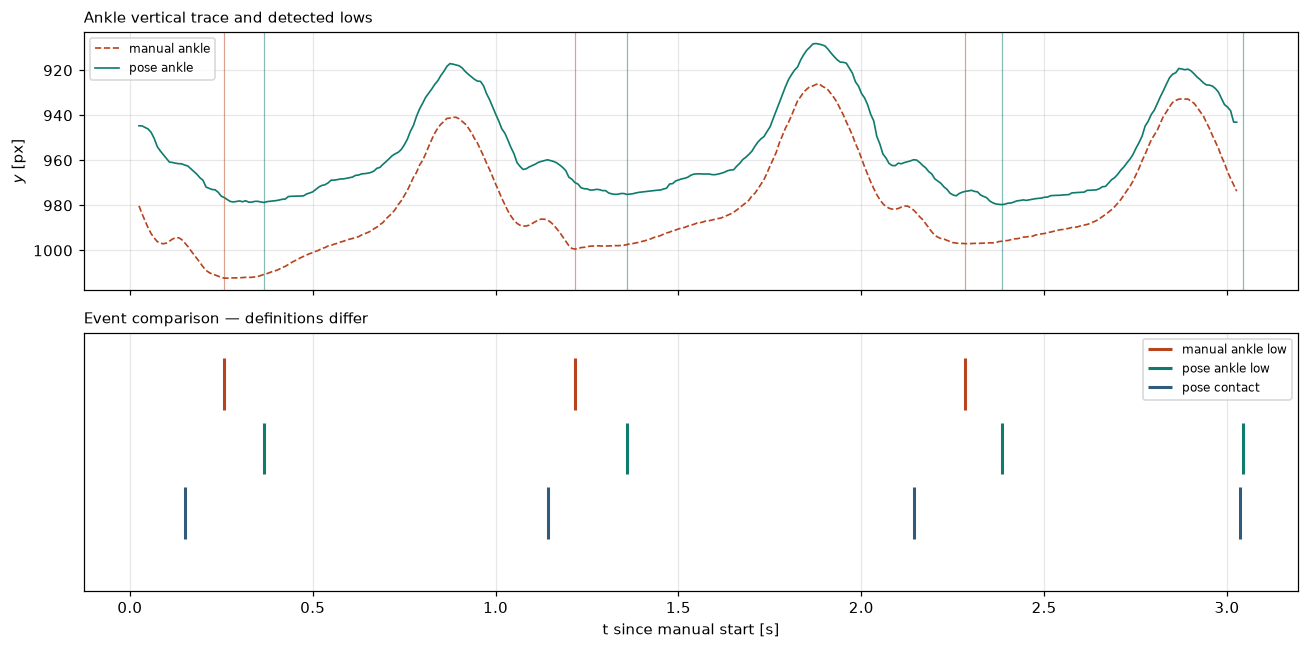

In [13]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

axes[0].plot(ankle.t_rel, ankle.ankle_y_px, color="#b8431f", lw=1.1, ls="--", label="manual ankle")
axes[0].plot(ankle.t_rel, ankle.pose_ankle_y_px, color="#0f7b6c", lw=1.1, label="pose ankle")
for _, event in manual_events.iterrows():
    axes[0].axvline(event["t_rel"], color="#b8431f", lw=0.8, alpha=0.5)
for _, event in pose_lows.iterrows():
    axes[0].axvline(event["t_rel"], color="#0f7b6c", lw=0.8, alpha=0.5)
axes[0].set_ylabel("$y$ [px]")
axes[0].invert_yaxis()
axes[0].legend(fontsize=8)
axes[0].set_title("Ankle vertical trace and detected lows", loc="left", fontsize=10)

axes[1].vlines(manual_events["t_rel"], 2.6, 3.0, color="#b8431f", lw=2, label="manual ankle low")
axes[1].vlines(pose_lows["t_rel"], 2.1, 2.5, color="#0f7b6c", lw=2, label="pose ankle low")
axes[1].vlines(contacts["t_rel"], 1.6, 2.0, color="#315b7d", lw=2, label="pose contact")
axes[1].set_ylim(1.2, 3.2)
axes[1].set_yticks([])
axes[1].set_xlabel("t since manual start [s]")
axes[1].legend(fontsize=8, loc="upper right")
axes[1].set_title("Event comparison — definitions differ", loc="left", fontsize=10)

fig.tight_layout()
plt.show()


In [14]:
comparison = merged[
    [
        "frame",
        "t_rel",
        "pts_s",
        "ankle_x_px",
        "ankle_y_px",
        "pose_ankle_x_px",
        "pose_ankle_y_px",
        "pose_ankle_vis",
        "pose_ankle_valid",
        "foot_x_px",
        "foot_y_px",
        "foot_vis",
        "foot_valid",
        "waist_x_px",
        "waist_y_px",
        "sacrum_x_px",
        "sacrum_y_px",
        "sacrum_vis",
        "sacrum_valid",
    ]
].copy()
comparison["ankle_dx_px"] = comparison["pose_ankle_x_px"] - comparison["ankle_x_px"]
comparison["ankle_dy_px"] = comparison["pose_ankle_y_px"] - comparison["ankle_y_px"]
comparison["foot_dx_px"] = comparison["foot_x_px"] - comparison["ankle_x_px"]
comparison["foot_dy_px"] = comparison["foot_y_px"] - comparison["ankle_y_px"]
comparison["sacrum_dx_px"] = comparison["sacrum_x_px"] - comparison["waist_x_px"]
comparison["sacrum_dy_px"] = comparison["sacrum_y_px"] - comparison["waist_y_px"]

comparison.to_csv(OUT_CSV, index=False)
print(f"wrote {OUT_CSV} ({len(comparison)} rows)")

display(
    pd.DataFrame(
        {
            "proxy": stats.index,
            "centered_RMSE_x_px": stats["centered_rmse_x_px"].to_numpy(),
            "centered_RMSE_y_px": stats["centered_rmse_y_px"].to_numpy(),
            "centered_RMSE_r_px": stats["centered_rmse_r_px"].to_numpy(),
            "mean_dx_px": stats["mean_dx_px"].to_numpy(),
            "mean_dy_px": stats["mean_dy_px"].to_numpy(),
        }
    ).round(2)
)


wrote /Users/rifusaki/localRepos/uni/invexp/walkTest/pose/001_manual_vs_pose.csv (387 rows)


,proxy,centered_RMSE_x_px,centered_RMSE_y_px,centered_RMSE_r_px,mean_dx_px,mean_dy_px
0,ankle,4.56,7.02,8.37,-1.51,-23.59
1,foot (heel/toe),18.65,22.31,29.08,-19.69,25.28
2,sacrum,6.58,7.47,9.95,-32.95,68.06


## Reading these results

- **The ankle is the correct comparison for manual mass B.** MediaPipe `left_ankle` gives a centred RMSE of about 8 px, versus about 29 px for the heel/foot-index proxy. The earlier validation used the heel/toe point, which introduced a large systematic shape error. The foot row is kept only as a sensitivity check.
- **Sacrum agrees well in shape.** The hip midpoint is a stable pelvis proxy; its raw offset reflects marker placement, not model noise. Centred RMSE is about 10 px.
- **Raw offsets are not errors.** The manual waist marker and the MediaPipe hip midpoint are different anatomical points. Centred RMSE and Bland–Altman are the meaningful comparisons.
- **No interpolation.** The waist gaps remain gaps in every plot and statistic.
- **Event definitions are not interchangeable.** The manual notebook detects ankle vertical lows. The pose pipeline detects forward-foot events. The "pose ankle low" row applies the manual algorithm to the matching MediaPipe ankle, so it is a like-for-like timing check. A delay between manual lows and pipeline contacts is expected because the definitions differ.
- **The existing `001_validation.json` is a different comparison.** It used the heel/foot-index proxy and the package helper `manual_contact_events` with a pixel-depth threshold, which selected earlier local maxima than the manual notebook. This notebook reproduces the manual notebook's `find_events` (0.03 annotation-unit depth) so the event table is traceable to the original analysis.
- **Do not differentiate pose to estimate impact acceleration.** At 120 fps, landmark noise dominates the second derivative, and impact content extends well above the frame rate. Use the BMI160 channels for impact magnitude and transmission.
